# Llegir les dades


In [311]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import geopandas as gpd
dataset_csv = pd.read_csv(r"../../Speculation-Map/Data/TouristicRentals/prova2025.csv",
                       index_col=0,dtype=object)



# Comptar allotjaments turístics per codi de municipi

In [312]:
conteo_municipios = (
    dataset_csv["codi_municipi_idescat"]
    .value_counts()
    .reset_index()
)
conteo_municipios.columns = ["codi_municipi_idescat", "NombreEdificis"]


conteo_municipios.rename(columns={"codi_municipi_idescat": "CODIMUNI"},inplace=True)
print(conteo_municipios)

C:\Users\user\AppData\Local\Temp\ipykernel_7408\2842496880.py:9: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  conteo_municipios.rename(columns={"codi_municipi_idescat": "CODIMUNI"},inplace=True)


    CODIMUNI  NombreEdificis
0     080193           11391
1     439057            7258
2     171523            5417
3     430385            3854
4     170470            3692
..       ...             ...
919   430666               1
920   250851               1
921   430347               1
922   250411               1
923   250740               1

[924 rows x 2 columns]


# Merge del mapa amb el compteig d'habitatges

In [313]:
municipis=gpd.read_file("../../Speculation-Map/Data/CatalunyaMapMunicipalities.json").to_crs(25831)
municipis = municipis.merge(conteo_municipios, on="CODIMUNI", how="left", validate="one_to_one")

In [314]:
municipis

,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,CODIPROV,NOMPROV,CAPPROV,geometry,NombreEdificis
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((410315.774 4598888.867, 410075...",7.0
1,080023,Aguilar de Segarra,Aguilar de Segarra,43.2198,07,Bages,Manresa,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((385155.598 4625034.944, 384697...",5.0
2,080039,Alella,Alella,9.6346,21,Maresme,Mataró,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((440348.026 4596213.927, 440338...",150.0
3,080044,Alpens,Alpens,13.7788,43,Lluçanès,Prats de Lluçanès,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((425142.962 4665930.715, 424829...",15.0
4,080057,l'Ametlla del Vallès,l'Ametlla del Vallès,14.0885,41,Vallès Oriental,Granollers,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((436871.133 4617049.619, 436914...",25.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
942,439039,Camarles,Camarles,30.0157,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((301288.757 4521580.722, 301179...",61.0
943,439044,l'Aldea,l'Aldea,30.4743,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((298373.126 4520080.954, 298283...",34.0
944,439057,Salou,Salou,15.1248,36,Tarragonès,Tarragona,04,Camp de Tarragona,Tarragona,43,Tarragona,Tarragona,"MULTIPOLYGON (((343971.449 4551180.512, 343522...",7258.0
945,439060,l'Ampolla,l'Ampolla,35.6196,09,Baix Ebre,Tortosa,05,Terres de l'Ebre,Tortosa,43,Tarragona,Tarragona,"MULTIPOLYGON (((305434.379 4524718.838, 305365...",698.0


# Mapa d'habitatges per municipi

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

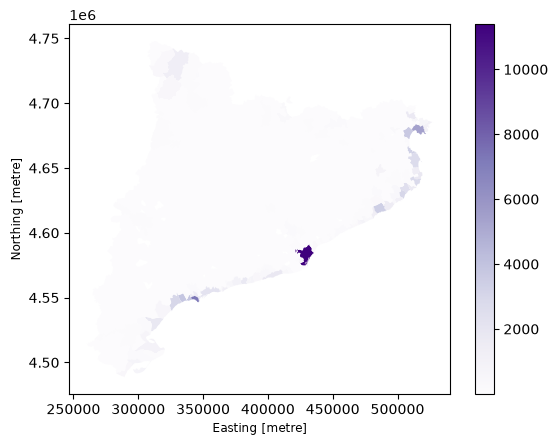

In [316]:

municipis.plot(column="NombreEdificis", cmap="Purples", legend=True)

# Llegir el dataset d'habitants

In [ ]:
habitants = gpd.read_file("../../Speculation-Map/Data/Habitants.csv")
habitants


# Reordenem la taula i fem una copia del codi de municipi per a que no sigui un index, sino una columna

In [ ]:
habitants1 = habitants.pivot(index="MUN",columns="SEX",values="value")
habitants1["MUN_COPY"] = habitants1.index
habitants1

# Fem que la columna de codi de municipi es digui igual que la del merge anterior

In [ ]:
habitants1.rename(columns={"MUN_COPY": "CODIMUNI"},inplace=True)
habitants1

# Afegim la columna d'habitants a la llista

In [ ]:
municipis_merged = municipis.merge(habitants1, on="CODIMUNI", how="left", validate="one_to_one")
municipis_merged

In [ ]:
municipis_merged["TOTAL"]=pd.to_numeric(municipis_merged["TOTAL"], errors="coerce") #Ha calgut passar de string a float la columna TOTAL

# Creem una nova columna que sigui la fracció entre Habitatges/Habitants

In [ ]:
municipis_merged["fraccio"] = municipis_merged["NombreEdificis"]/municipis_merged["TOTAL"]
municipis_merged

# Per comarca

In [ ]:
total_hab_com=municipis_merged.groupby("CODICOMAR",as_index=False).agg(inhab_com=("TOTAL",lambda s: s.sum()))

total_hab_com=municipis_merged.merge(total_hab_com,on="CODICOMAR",how="left",validate="many_to_one")
total_hab_com

In [ ]:
total_tour_com=total_hab_com.groupby("CODICOMAR",as_index=False).agg(tour_com=("NombreEdificis",lambda s: s.sum()))

total_tour_com=total_hab_com.merge(total_tour_com,on="CODICOMAR",how="left",validate="many_to_one")
total_tour_com

In [ ]:
total_tour_com["fraccio_com"]=total_tour_com["tour_com"]/total_tour_com["inhab_com"]
total_tour_com

# Plotejem el mapa en funció de la columna fracció (afegim escala i orientació)

In [ ]:
def add_scale_bar(ax, length_km=50, loc=(0.05, 0.002)):
    """Draw a scale bar of length_km on an Axes whose coordinates are in metres."""
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x = x0 + loc[0] * (x1 - x0)
    y = y0 + loc[1] * (y1 - y0)
    ax.plot([x, x + length_km * 1000], [y, y], color="black", lw=3)
    ax.text(x + length_km * 500, y + 0.015 * (y1 - y0), f"{length_km} km", ha="center", va="bottom", fontsize=9)


def add_north_arrow(ax, loc=(0.93, 0.93)):
    ax.annotate("N", xy=loc, xytext=(loc[0], loc[1] - 0.1), xycoords="axes fraction",
                ha="center", va="center", fontsize=12, fontweight="bold",
                arrowprops={"arrowstyle": "-|>", "color": "black"})

In [ ]:
from matplotlib.colors import LogNorm # En escala logarítmica
fig, axs = plt.subplots(1, 2, figsize=(11, 5),  layout="constrained")
total_tour_com.plot(column="fraccio", cmap="Purples", norm=LogNorm(),legend=True, ax=axs[0],legend_kwds={"shrink": 0.7})
total_tour_com.plot(column="fraccio_com",cmap="Purples",norm=LogNorm(),legend=True,ax=axs[1],legend_kwds={"shrink": 0.7})
axs[0].set_title("Habitatges turístics/habitants per municipi")
axs[1].set_title("Habitatges turístics/habitants per comarca")

for ax in axs:
    ax.set_axis_off()
#add_scale_bar(axs)
#add_north_arrow(axs)
plt.show()

# Plotejem per quartils

In [ ]:
total_tour_com["quintile"] = pd.qcut(total_tour_com["fraccio"], 4, labels=["lowest 20%", "2", "3", "highest 20%"])
total_tour_com["quintile_com"] = pd.qcut(total_tour_com["fraccio_com"], 4, labels=["lowest 20%", "2", "3", "highest 20%"])

In [ ]:
from matplotlib.colors import LogNorm # En escala logarítmica
fig, axs = plt.subplots(1, 2, figsize=(11, 5),  layout="constrained")
total_tour_com.plot(column="quintile", cmap="Purples", norm=LogNorm(),legend=True, ax=axs[0])
total_tour_com.plot(column="quintile_com",cmap="Purples",norm=LogNorm(),legend=True,ax=axs[1])
axs[0].set_title("Habitatges turístics/habitants per municipi")
axs[1].set_title("Habitatges turístics/habitants per comarca")

for ax in axs:
    ax.set_axis_off()
#add_scale_bar(axs)
#add_north_arrow(axs)
plt.show()

In [ ]:
municipis_merged["log"]=np.log(municipis_merged["fraccio"])
municipis_merged["logquintile"] = pd.qcut(municipis_merged["log"], 4, labels=["1", "2", "3", "4"])
municipis_merged["logquintile"]=pd.to_numeric(municipis_merged["logquintile"], errors="coerce")
municipis_merged["Edificis/10000Habitants"]=municipis_merged["fraccio"]*10000
municipis_merged.head()


In [ ]:
import plotly.express as px

municipis=gpd.read_file("../../Speculation-Map/Data/CatalunyaMapMunicipalities.json")

municipis_merged["geometry"]=municipis["geometry"]

fig = px.choropleth_map(
    municipis_merged, geojson=municipis_merged.__geo_interface__, locations="CODIMUNI",
    featureidkey="properties.CODIMUNI", color="logquintile", color_continuous_scale="Purples",
    hover_data=["NOMMUNI","NOMCOMAR","Edificis/10000Habitants"],
    center={"lat": 41.7, "lon": 1.7}, zoom=6.3, map_style="carto-positron",
    labels={"logquintile": "rank"},
)

fig.update_layout(margin={"r": 0, "t": 0, "l": 0, "b": 0})
fig

In [ ]:
total_tour_com["log_com"]=np.log(total_tour_com["fraccio_com"])
total_tour_com["logquintile_com"]=pd.qcut(total_tour_com["log_com"],4,labels=["1", "2", "3", "4"])
total_tour_com["logquintile_com"]=pd.to_numeric(total_tour_com["logquintile_com"],errors="coerce")
com=total_tour_com.groupby("CODICOMAR",as_index=False).agg(rank=("logquintile_com",lambda s: s.mean()), NOMCOMAR=("NOMCOMAR", "first"),fraccio_com=("fraccio",lambda s:s.mean()),inhab_com=("inhab_com","first"))
com["Edificis/10000Habitants"]=com["fraccio_com"]*10000


In [ ]:
import plotly.express as px

comarques=gpd.read_file("../../Speculation-Map/Data/CatalunyaMapComarques.json")



fig = px.choropleth_map(
    com, geojson=comarques.__geo_interface__, locations="CODICOMAR",
    featureidkey="properties.CODICOMAR", color="rank", color_continuous_scale="Purples",
    hover_data=["NOMCOMAR","Edificis/10000Habitants"],
    center={"lat": 41.7, "lon": 1.7}, zoom=6.3, map_style="carto-positron",
    labels={"Edificis/10000Habitants": "Edificis/10000Habitants"},
)

fig.update_layout(margin={"r": 0, "t": 0, "l": 0, "b": 0})
fig